In [1]:
import sys
sys.path.append('../../py')
%load_ext autoreload
%autoreload 2



import common.flow_map as flow_map
import common.network_utils as network_utils
import common.datasets as datasets
import ml_collections
import ot



import jax
import jax.flatten_util
import jax.numpy as jnp
import numpy as np
import pickle
import flax
from flax.serialization import from_bytes, msgpack_restore
import importlib
from tqdm.auto import tqdm

2025-09-30 18:17:20.237745: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759270640.253732 2632716 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759270640.258479 2632716 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1759270640.271416 2632716 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1759270640.271431 2632716 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1759270640.271433 2632716 computation_placer.cc:177] computation placer alr

In [2]:
prng_key = jax.random.PRNGKey(42)

# Construct model and dataset

## Load example config (all models use same network)

In [3]:
cfg_path = "configs.9_9_25_checker_loss_method_comparison"
cfg_module = importlib.import_module(cfg_path)
cfg = cfg_module.get_config(
    slurm_id=0, 
    dataset_location="/n/netscratch/albergo_lab/Everyone/",
    output_folder="/n/holylabs/LABS/albergo_lab/Everyone/nmboffi/lmm/checker"
)

## Construct data

In [4]:
cfg, ds, prng_key = datasets.setup_target(cfg, prng_key)

I0000 00:00:1759270677.383504 2632716 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8063 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:ca:00.0, compute capability: 8.0


In [5]:
x1s = next(ds)
sample_rho0 = datasets.setup_base(cfg, x1s[0])

## Construct network

In [6]:
net, params, prng_key = flow_map.initialize_flow_map(cfg.network, x1s[0], prng_key)

Number of parameters: 1054210


# Load model parameters

In [42]:
output_folder = "/n/netscratch/albergo_lab/Everyone/nmboffi/checker"

file_names = [
    "checker_lsd_stopgrad_convex_diag75_9_9_15.pkl",
    "checker_esd_stopgrad_convex_diag75_9_9_15.pkl",
    "checker_pfmm_shortcut_stopgrad_convex_diag75_9_9_15.pkl",
    "checker_pfmm_uniform_stopgrad_convex_diag75_9_9_15.pkl"
]
loss_types = ["LSD", "ESD", "PSD-M", "PSD-U"]

data = {}
for kk, file_name in enumerate(file_names):
    file = f"{output_folder}/{file_name}"
    loss_type = loss_types[kk]
    with open(file, "rb") as f:
        raw_bytes = f.read()
        raw_state = msgpack_restore(raw_bytes)

        data[loss_type] = {}
        data[loss_type]['params'] = raw_state['params']
        data[loss_type]['ema_params'] = raw_state['ema_params']

# Generate model samples

In [48]:
nsteps_arr = [1, 2, 4, 8, 16]
nsamples = 64_000
bs = 512
nbatches = nsamples // bs
assert(nsamples % bs == 0)

samples = {}
for loss_type in data.keys():
    samples[loss_type] = np.zeros((len(nsteps_arr), nsamples, 2))
    
    for kk, nsteps in tqdm(enumerate(nsteps_arr)):
        for curr_batch in range(nbatches):
            lb = curr_batch * bs
            ub = lb + bs
            prng_key = jax.random.split(prng_key)[0]

            x0s = sample_rho0(bs, prng_key)
            samples[loss_type][kk, lb:ub] = flow_map.batch_sample(
                net.apply,
                data[loss_type]['ema_params']['0.999'],
                # data[loss_type]['params'],
                x0s,
                nsteps,
                -jnp.ones_like(x0s)
            )

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

# Compute KL

In [49]:
import jax
import jax.numpy as jnp
from functools import partial

@jax.jit
def eval_checkerboard(x, n_squares=4):
    """
    Evaluate the checkerboard probability density at point(s) x.
    
    Args:
        x: (..., 2) array of points in [-1, 1]^2
        n_squares: number of squares per dimension
    
    Returns:
        (...,) array of density values
    """
    # Map from [-1, 1]^2 to [0, 1]^2
    x_unit = (x[..., 0] + 1) / 2
    y_unit = (x[..., 1] + 1) / 2
    
    # Determine which square each point falls into
    x_idx = jnp.floor(x_unit * n_squares).astype(jnp.int32)
    y_idx = jnp.floor(y_unit * n_squares).astype(jnp.int32)
    
    # White squares have (x_idx + y_idx) % 2 == 0
    is_white = (x_idx + y_idx) % 2 == 0
    
    # Density: uniform on white squares, 0 on black
    # Total area = 4, white area = 2, so density = 1/2 on white squares
    density = jnp.where(is_white, 0.5, 0.0)
    
    return density


@partial(jax.jit, static_argnums=(1,))
def compute_histogram_density(samples, n_bins=50):
    """
    Compute histogram as a probability density.
    
    Args:
        samples: (N, 2) array of samples
        n_bins: number of bins per dimension
    
    Returns:
        hist_density: (n_bins, n_bins) histogram as density
        edges: (n_bins + 1,) bin edges
    """
    edges = jnp.linspace(-1, 1, n_bins + 1)
    
    # Compute histogram counts
    hist_density, _, _ = jnp.histogram2d(
        samples[:, 0], samples[:, 1],
        bins=[edges, edges],
        density=True,
    )

    return hist_density, edges


@partial(jax.jit, static_argnums=(2, 3))
def compute_kl_quadrature(hist_density_model, edges, n_squares=4, eps=1e-10):
    """
    Compute KL divergence KL(P_target || P_model) using quadrature.
    Both p and q are probability densities.
    
    Args:
        hist_density_model: (n_bins, n_bins) histogram density from model
        edges: (n_bins + 1,) bin edges
        n_squares: number of checkerboard squares
        eps: small value for numerical stability
    
    Returns:
        KL divergence value
    """
    n_bins = len(edges) - 1
    bin_width = edges[1] - edges[0]
    bin_area = bin_width ** 2
    
    # Compute bin centers
    bin_centers = (edges[:-1] + edges[1:]) / 2
    x_centers, y_centers = jnp.meshgrid(bin_centers, bin_centers, indexing='ij')
    grid_points = jnp.stack([x_centers.ravel(), y_centers.ravel()], axis=-1)
    
    # Evaluate true checkerboard density at bin centers
    p_target_flat = eval_checkerboard(grid_points, n_squares)
    p_target = p_target_flat.reshape(n_bins, n_bins)
    
    # Add epsilon to model density for numerical stability
    q_model = hist_density_model + eps
    
    # KL divergence via quadrature:
    # KL = ∫∫ p(x,y) log(p(x,y)/q(x,y)) dx dy
    # ≈ Σ p(x_i, y_j) log(p(x_i, y_j)/q(x_i, y_j)) * bin_area
    # Only sum over bins where p_target > 0 (white squares)
    mask = p_target > 0
    kl = jnp.sum(
        jnp.where(mask,
                  p_target * jnp.log(p_target / q_model) * bin_area,
                  0.0)
    )
    
    return kl


# Alternative: More accurate quadrature using sub-grid within each bin
@partial(jax.jit, static_argnums=(2, 3, 4))
def compute_kl_quadrature_refined(hist_density_model, edges, n_squares=4, n_quad=5, eps=1e-10):
    """
    More accurate KL computation using sub-grid quadrature within each bin.
    Useful for bins that straddle checkerboard boundaries.
    
    Args:
        hist_density_model: (n_bins, n_bins) histogram density from model  
        edges: (n_bins + 1,) bin edges
        n_squares: number of checkerboard squares
        n_quad: number of quadrature points per bin dimension
        eps: small value for numerical stability
    
    Returns:
        KL divergence value
    """
    n_bins = len(edges) - 1
    bin_width = edges[1] - edges[0]
    
    # Add epsilon to model density
    q_model = hist_density_model + eps
    
    kl = 0.0
    for i in range(n_bins):
        for j in range(n_bins):
            # Create sub-grid within this bin
            x_quad = jnp.linspace(edges[i], edges[i+1], n_quad)
            y_quad = jnp.linspace(edges[j], edges[j+1], n_quad)
            xx, yy = jnp.meshgrid(x_quad, y_quad, indexing='ij')
            quad_points = jnp.stack([xx.ravel(), yy.ravel()], axis=-1)
            
            # Evaluate true density at quadrature points
            p_vals = eval_checkerboard(quad_points, n_squares)
            
            # Model density is constant within bin
            q_val = q_model[i, j]
            
            # Quadrature for this bin
            # Note: we're using uniform quadrature weights
            quad_weight = (bin_width / n_quad) ** 2
            integrand = jnp.where(p_vals > 0,
                                 p_vals * jnp.log(p_vals / q_val),
                                 0.0)
            kl += jnp.sum(integrand) * quad_weight
    
    return kl


# Batch processing
@partial(jax.jit, static_argnums=(1, 2))
def batch_compute_kl(samples_batch, n_bins=50, n_squares=4):
    """
    Compute KL for a batch of sample sets.
    
    Args:
        samples_batch: (batch_size, N, 2) array of samples
        n_bins: number of histogram bins
        n_squares: number of checkerboard squares
    
    Returns:
        (batch_size,) array of KL values
    """
    def compute_single_kl(samples):
        hist_density, edges = compute_histogram_density(samples, n_bins)
        kl = compute_kl_quadrature(hist_density, edges, n_squares)
        return kl
    
    return jax.vmap(compute_single_kl)(samples_batch)


# Usage remains the same
n_bins = 50
n_squares = 4

kl_results = {}
for loss_type in samples.keys():
    model_samples = jnp.array(samples[loss_type])
    kl_values = batch_compute_kl(model_samples, n_bins, n_squares)
    kl_results[loss_type] = kl_values
    
    print(f"\nLoss type: {loss_type}")
    print("KL divergences:")
    for nsteps, kl in zip(nsteps_arr, kl_values):
        print(f"  nsteps={nsteps:2d}: KL = {kl:.4f}")


Loss type: LSD
KL divergences:
  nsteps= 1: KL = 0.0864
  nsteps= 2: KL = 0.0765
  nsteps= 4: KL = 0.0708
  nsteps= 8: KL = 0.0699
  nsteps=16: KL = 0.0710

Loss type: ESD
KL divergences:
  nsteps= 1: KL = 0.0983
  nsteps= 2: KL = 0.0921
  nsteps= 4: KL = 0.0834
  nsteps= 8: KL = 0.0816
  nsteps=16: KL = 0.0751

Loss type: PSD-M
KL divergences:
  nsteps= 1: KL = 0.1456
  nsteps= 2: KL = 0.0891
  nsteps= 4: KL = 0.0812
  nsteps= 8: KL = 0.0717
  nsteps=16: KL = 0.0689

Loss type: PSD-U
KL divergences:
  nsteps= 1: KL = 0.1113
  nsteps= 2: KL = 0.1067
  nsteps= 4: KL = 0.0747
  nsteps= 8: KL = 0.0727
  nsteps=16: KL = 0.0679


# Make figures

In [50]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import numpy as np
from typing import Optional

mpl.rcParams.update({
    "axes.grid": True,
    "axes.grid.which": "both",
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 0.25,
    "ytick.major.width": 0.25,
    "xtick.minor.width": 0.15,
    "ytick.minor.width": 0.15,
    "axes.linewidth": 0.25,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
    "xtick.minor.size": 1.0,
    "ytick.minor.size": 1.0,
    "lines.antialiased": True,
    "axes.facecolor": "white",
    "grid.color": "0.9",
    "grid.alpha": 0.5,
    "text.usetex": True,
    "font.family": "serif",
    "figure.figsize": (8, 4),
    "figure.titlesize": 7.5,
    "font.size": 10,
    "legend.fontsize": 7.5,
    "figure.dpi": 300,
})

## Full plot

In [74]:
def plot_checker_samples(
    samples: dict[str, np.ndarray],
    nsteps_arr: list[int],
    npts_plot: int,
    target_samples: np.ndarray | None = None,
    *,
    figsize_per_panel: tuple[float, float] = (4, 4),
    fontsize: float = 12.5,
    savepath: str | None = None,
) -> None:
    """
    Visualise generated 2-D samples on the checkerboard.

    Parameters
    ----------
    samples
        Dict mapping loss_name → array with shape
        (len(nsteps_arr), nsamples, 2).
    nsteps_arr
        Ordered list of step counts (must match axis 0 of each array).
    target_samples
        Optional (N, 2) array of true checker samples to overlay.
        If provided, they appear in every column.
    figsize_per_panel
        (width, height) in inches for a single subplot.
    fontsize
        Font size for titles and tick labels.
    savepath
        If given, save the figure to this path (dpi=300); otherwise
        just show it.
    """
    sns.set_palette("deep")

    loss_types = list(samples.keys())
    nrows, ncols = len(loss_types), len(nsteps_arr)
    fw, fh = figsize_per_panel

    fig, axs = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(fw * ncols, fh * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    # Ensure axs is 2-D even when nrows == 1
    axs = np.atleast_2d(axs)

    # Common axis limits for the checkerboard
    xlim = ylim = (-1.25, 1.25)

    for row_idx, loss_name in enumerate(loss_types):
        arr = samples[loss_name]                      # (nsteps, N, 2)

        for col_idx, nsteps in enumerate(nsteps_arr):
            ax = axs[row_idx, col_idx]

            # Titles across the top row
            if row_idx == 0:
                ax.set_title(fr"$N={nsteps}$", fontsize=fontsize)

            # Row labels on the leftmost column
            if col_idx == 0:
                ax.set_ylabel(loss_name, fontsize=fontsize)

            # Plot target points, if provided
            if target_samples is not None:
                ax.scatter(
                    target_samples[:npts_plot, 0],
                    target_samples[:npts_plot, 1],
                    s=0.1,
                    alpha=0.5,
                    marker="o",
                    c="C0",
                    label="target" if (row_idx, col_idx) == (0, 0) else None,
                )

            # Plot generated samples
            ax.scatter(
                arr[col_idx, :npts_plot, 0],
                arr[col_idx, :npts_plot, 1],
                s=0.20,
                alpha=0.7,
                marker="o",
                c="black",
                label="model" if (row_idx, col_idx) == (0, 0) else None,
            )

            # Cosmetic tweaks
            ax.set_xlim(*xlim)
            ax.set_ylim(*ylim)
            ax.set_aspect("equal")
            ax.grid(which="both", axis="both", color="0.90", alpha=0.2)
            ax.tick_params(axis="both", labelsize=fontsize)
            ax.set_xticklabels([])
            ax.set_yticklabels([])

    if savepath:
        fig.savefig(savepath, dpi=300)
        print(f"figure written to {savepath}")
    else:
        plt.show()

figure written to plots/checker_full_9_30_25.png


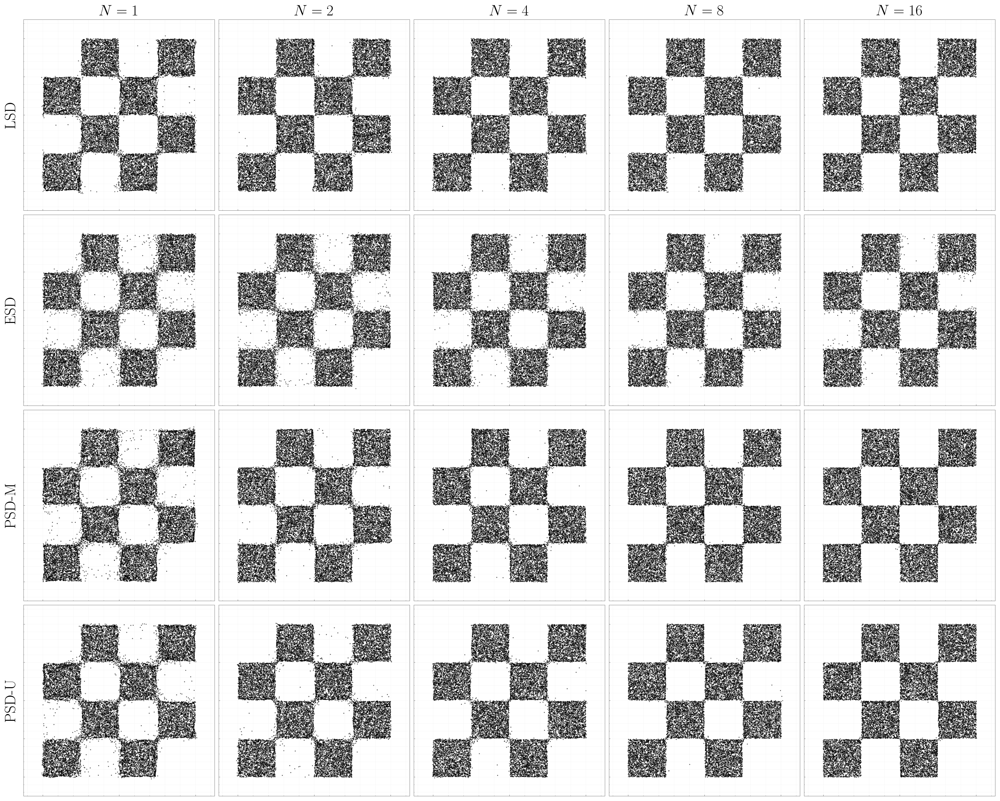

In [75]:
## checkpoint 15
plot_checker_samples(
    samples, 
    nsteps_arr, 
    npts_plot=20_000,
    target_samples=None,
    fontsize=22,
    savepath='plots/checker_full_9_30_25.png'
)

## Reduced plot

In [76]:
from typing import Dict, List, Tuple

def plot_checker_samples_by_method(
    samples: Dict[str, np.ndarray],
    *,
    nsteps_arr: List[int],
    steps_rows: List[int] = (1, 4),        # rows “N = 1”, “N = 4”
    npts_plot: int = 10_000,
    target_samples: Optional[np.ndarray] = None,
    figsize_per_panel: Tuple[float, float] = (4, 4),
    fontsize: float = 12.5,
    savepath: Optional[str] = None,
) -> None:
    """
    Visualise 2-D checkerboard samples with
        * rows   → chosen integration steps  (e.g. N = 1, 4)
        * columns→ different loss / training objectives.

    Parameters
    ----------
    samples
        Dict  loss_name → array  (len(nsteps_arr), nsamples, 2).
    nsteps_arr
        Master list of step counts used when populating ``samples``.
    steps_rows
        Subset of ``nsteps_arr`` to show as rows (order defines row order).
    npts_plot
        Maximum points to scatter per panel (uniform prefix slice).
    target_samples
        Optional (N, 2) array of true checker samples; over-plotted in every panel.
    figsize_per_panel
        Subplot size in inches.
    fontsize
        Tick‐label / title font size.
    savepath
        If given, save PNG to this path (dpi = 300); otherwise ``plt.show()``.
    """
    # --- sanity checks -----------------------------------------------------
    idx_rows = []
    for s in steps_rows:
        if s not in nsteps_arr:
            raise ValueError(f"step {s} not found in nsteps_arr")
        idx_rows.append(nsteps_arr.index(s))

    loss_types = list(samples.keys())                # columns
    nrows, ncols = len(steps_rows), len(loss_types)
    fw, fh = figsize_per_panel

    sns.set_palette("deep")
    fig, axs = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(fw * ncols, fh * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )
    axs = np.atleast_2d(axs)                         # ensure 2-D

    # common axis limits for the checkerboard
    xlim = ylim = (-1.25, 1.25)

    for col_idx, loss_name in enumerate(loss_types):
        arr = samples[loss_name]                     # (len(nsteps_arr), N, 2)

        for row_idx, (step, idx) in enumerate(zip(steps_rows, idx_rows)):
            ax = axs[row_idx, col_idx]

            # --- titles & labels ------------------------------------------
            if row_idx == 0:
                ax.set_title(loss_name, fontsize=fontsize)
            if col_idx == 0:
                ax.set_ylabel(fr"$N={step}$", fontsize=fontsize)

            # --- scatter points -------------------------------------------
            if target_samples is not None:
                ax.scatter(
                    target_samples[:npts_plot, 0],
                    target_samples[:npts_plot, 1],
                    s=0.25,
                    alpha=0.75,
                    marker="o", c="C0",
                    label="target" if (row_idx, col_idx) == (0, 0) else None,
                )

            ax.scatter(
                arr[idx, :npts_plot, 0],
                arr[idx, :npts_plot, 1],
                s=0.20,
                alpha=0.7,
                marker="o", 
                c="black",
                label="model" if (row_idx, col_idx) == (0, 0) else None,
            )

            # --- cosmetics -------------------------------------------------
            ax.set_xlim(*xlim)
            ax.set_ylim(*ylim)
            ax.set_aspect("equal")
            ax.grid(which="both", axis="both", color="0.90", alpha=0.2)
            ax.tick_params(axis="both", labelsize=fontsize)
            ax.set_xticklabels([])
            ax.set_yticklabels([])

    if savepath:
        fig.savefig(savepath, dpi=300)
        print(f"figure written to {savepath}")
    else:
        plt.show()

figure written to plots/checker_reduced_9_30_25.png


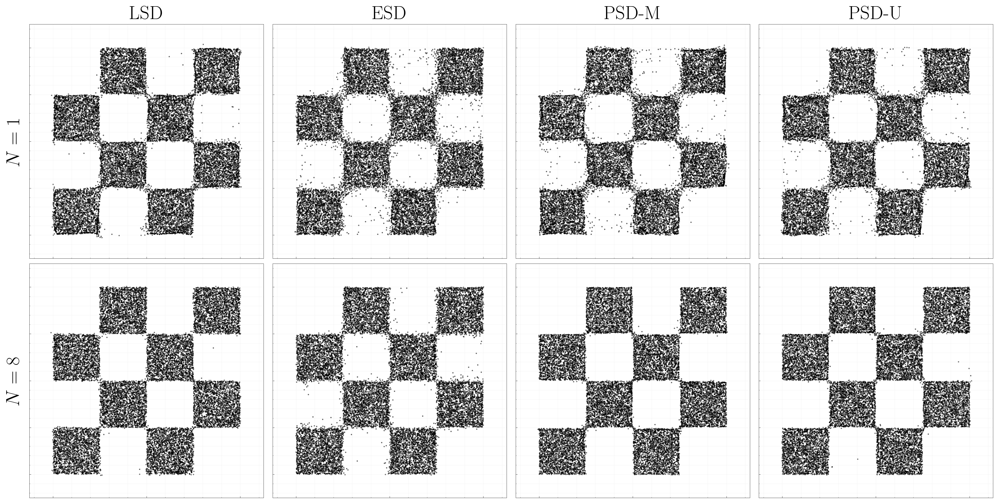

In [77]:
## checkpoint 15
plot_checker_samples_by_method(
    samples,                     # dict from earlier
    nsteps_arr=nsteps_arr,       # master list
    steps_rows=[1, 8],           # rows: 1-step and 4-step
    npts_plot=20_000,            # plot ≤15 k points
    target_samples=None,
    fontsize=22,
    # target_samples=x1s,          # ground-truth checker data
    # savepath="checker_grid.png", # or None to just display
    savepath='plots/checker_reduced_9_30_25.png'
)